# 05 — Edges, votes, and professional liars

A noisy image hides structure. Filters calm the noise, edge detectors reveal boundaries, the Hough transform lets edge pixels vote for lines, and RANSAC fits a model while refusing to trust everybody.

Our route is deliberately visual:

**noisy pixels → smoothing → edges → line evidence → robust fitting**

Least squares will appear only when it has a job to do. No one will be asked to admire a wall of derivatives for character development.

### Philosophical digression — what is this notebook really about?

Mostly, it is about finding meaningful lines in images—but the reusable story is broader: **calm the noise → extract useful evidence → fit a geometric model → survive bad evidence**. Hough works with image edges; least squares and RANSAC work with point coordinates, but all three are trying to turn an untidy crowd of measurements into structure.

Today that structure is a line. Another day it might be a circle, a plane, a camera transformation, or some other geometric creature demanding attention.

In [1]:
import cv2
import numpy as np

from _helpers.edges_hough_ransac import (
    make_line_points,
    make_line_scene,
    plot_canny_threshold_sweep,
    plot_edge_maps,
    plot_hough_detection,
    plot_hough_parameter_grid,
    plot_hough_voting_curves,
    plot_least_squares_outliers,
    plot_line_scene,
    plot_noise_smoothing_practice,
    plot_numbered_hough_segments,
    plot_ransac_parameter_grid,
    plot_ransac_result,
    plot_smoothing_combinations,
    plot_smoothing_comparison,
    plot_smoothing_kernel_sweep,
)

np.set_printoptions(precision=3, suppress=True)
print(f"OpenCV {cv2.__version__} | NumPy {np.__version__}")

OpenCV 4.14.0 | NumPy 2.5.4


## 1. Manufacture a small road crime scene

We use a synthetic grayscale scene so we know which structures are real and which pixels are merely making trouble. The diagonal lines will become our road-like targets; two suspiciously well-groomed trees provide curved and vertical boundaries so the algorithms cannot claim the exam was unfair.

> Curious how the road and its photosynthetically challenged trees are manufactured? [Notebook 05 helpers](./_helpers/edges_hough_ransac.py).

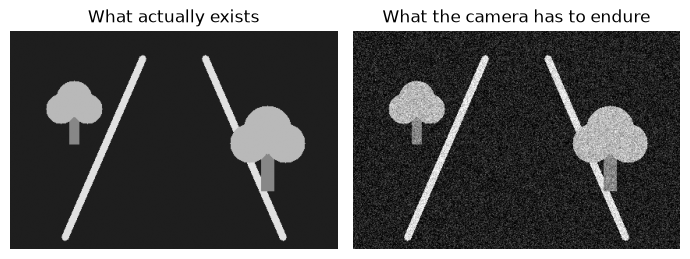

In [2]:
clean_scene, noisy_scene = make_line_scene()
plot_line_scene(clean_scene, noisy_scene)

## 2. Smoothing: ask neighbouring pixels to calm down

A filter kernel is a tiny grid that slides over the image. At every position it combines neighbouring pixels into a new value. This sliding weighted sum is **convolution**—although OpenCV usually handles the actual arithmetic while we retain our remaining daylight.

A **box filter** gives every neighbour equal influence. A **Gaussian filter** gives nearby pixels more influence than distant ones. Both reduce noise, but both also soften boundaries. Smoothing is therefore negotiation, not free cleaning.

> Further reading to provide comfort through its mere existence: [OpenCV image filtering](https://docs.opencv.org/4.x/d4/d13/tutorial_py_filtering.html).

> If arranging blur comparisons becomes your calling: [smoothing visualization helpers](./_helpers/edges_hough_ransac.py).

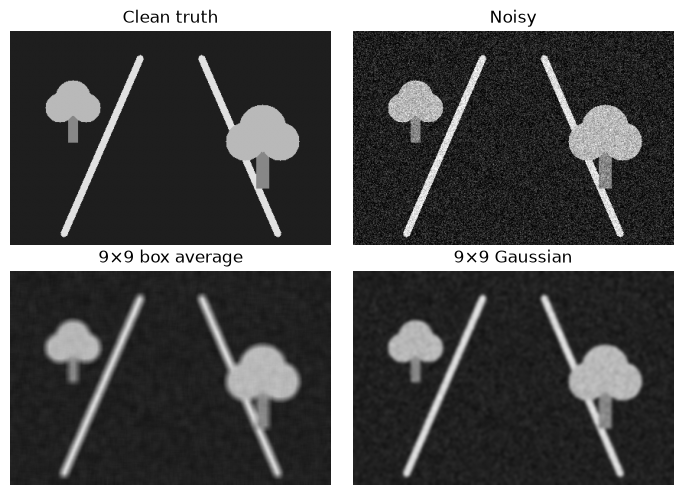

In [4]:
smoothing_kernel = (9, 9)
gaussian_sigma = 2.0

plot_smoothing_comparison(
    clean_scene, noisy_scene,
    kernel=smoothing_kernel,
    gaussian_sigma=gaussian_sigma,
);

### Practice 1 — Increase the noise: how differently do filters calm it?

Keep the scene and kernel frozen. Change `noise_sigma`, then compare the smoothing results directly.

> The smoothing grids live with the [notebook 05 helpers](./_helpers/edges_hough_ransac.py), safely away from tired civilians.

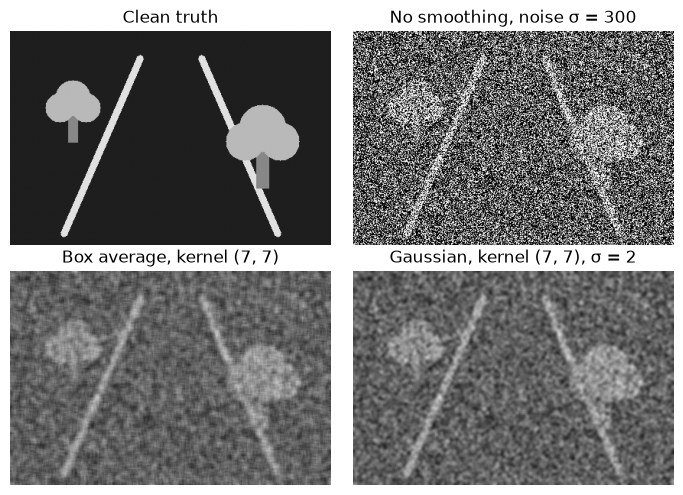

In [5]:
noise_sigma = 300
kernel_size = (7, 7)

clean_practice_scene, noisy_practice_scene = make_line_scene(noise_sigma=noise_sigma)
smoothed_versions = plot_noise_smoothing_practice(
    clean_practice_scene,
    noisy_practice_scene,
    noise_sigma,
    kernel_size,
)

#### How much neighbourhood is too much neighbourhood?

Try three kernel sizes while freezing the noisy image and Gaussian `sigmaX=2.0`. Larger kernels let more neighbours join the smoothing committee. For the Gaussian filter, the difference may become small once the kernel is already wide enough to contain most of the same bell-shaped weights.

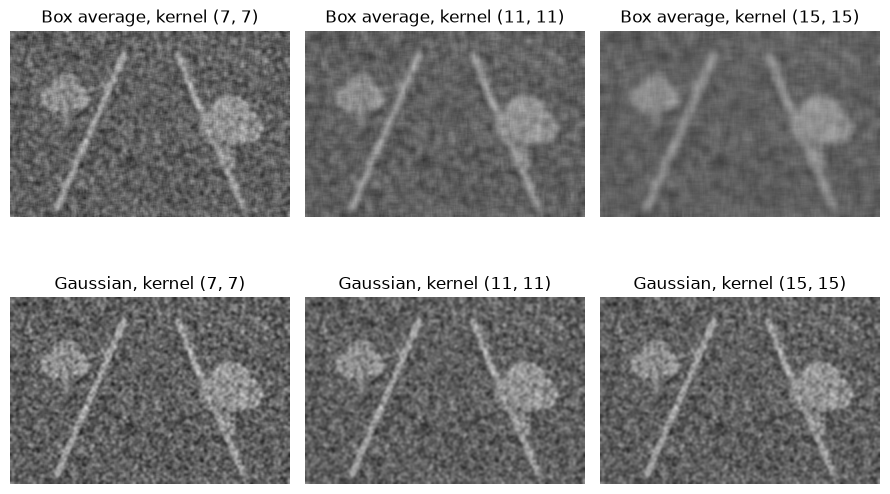

In [6]:
kernel_sizes = [(7, 7), (11, 11), (15, 15)]

plot_smoothing_kernel_sweep(noisy_practice_scene, kernel_sizes)

#### When one blur is not enough

Compare repeated and mixed filters using the same `(7, 7)` kernel. Every extra pass removes more noise but also negotiates away more real detail. Box→Gaussian and Gaussian→box should be nearly identical: convolution is effectively commutative, with only border handling and intermediate integer rounding permitted to cause minor disagreement.

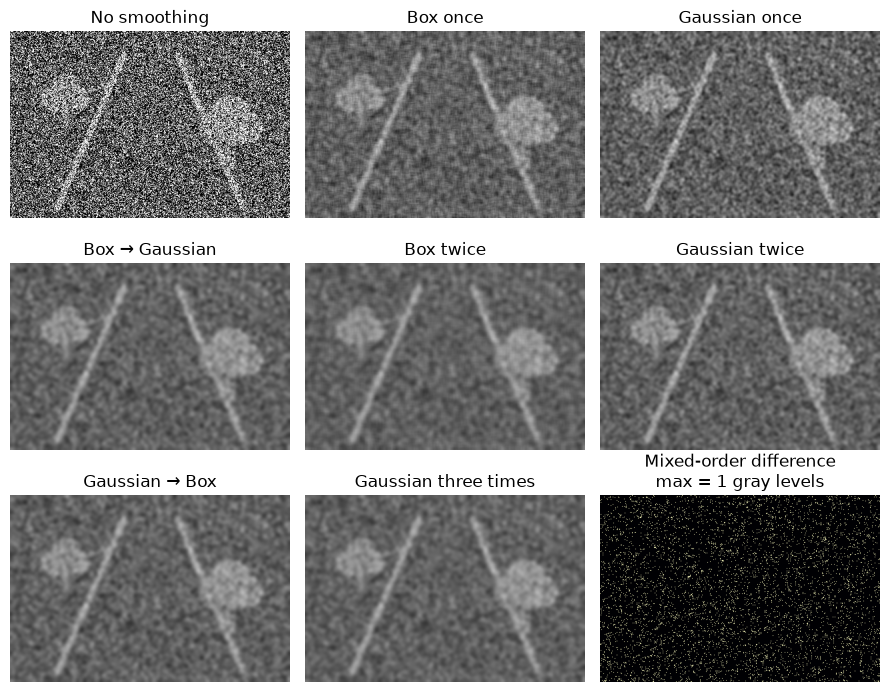

In [7]:
combination_kernel = (7, 7)

plot_smoothing_combinations(noisy_practice_scene, combination_kernel)

## 3. Border highlighting: look for sudden change

An edge is a place where brightness changes quickly. Derivative filters approximate that change using neighbouring pixels:

- **Sobel X** reacts strongly to left–right brightness change, so it highlights mostly vertical borders.
- **Sobel Y** reacts to top–bottom change, so it highlights mostly horizontal borders.
- Combining both gives gradient magnitude: *how strong is the change, regardless of direction?*
- **Canny** turns this into a thin binary edge map and applies additional rules so every mild complaint does not become an edge.

> Official reading for people who wish to know what the demon does after smoothing: [Sobel derivatives](https://docs.opencv.org/4.x/d2/d2c/tutorial_sobel_derivatives.html) and [Canny edge detection](https://docs.opencv.org/4.x/da/d22/tutorial_py_canny.html).

> Curious about the edge figure's stage machinery? [Edge visualization helper](./_helpers/edges_hough_ransac.py).

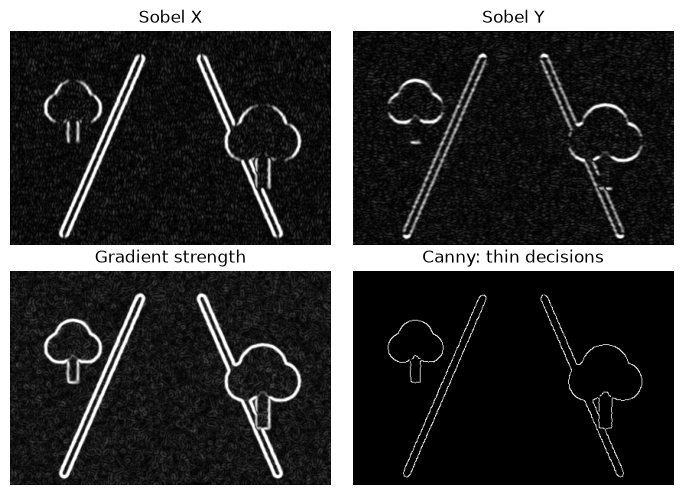

In [8]:
smoothed_for_edges = cv2.GaussianBlur(noisy_scene, (7, 7), sigmaX=1.4)
sobel_x = cv2.Sobel(smoothed_for_edges, cv2.CV_32F, 1, 0, ksize=3)
sobel_y = cv2.Sobel(smoothed_for_edges, cv2.CV_32F, 0, 1, ksize=3)
gradient_magnitude = cv2.magnitude(sobel_x, sobel_y)
edge_map = cv2.Canny(smoothed_for_edges, threshold1=50, threshold2=130)

plot_edge_maps(smoothed_for_edges, sobel_x, sobel_y, gradient_magnitude, edge_map)

### Practice 2 — Give Canny different standards

Freeze the noisy scene and Gaussian smoothing from Practice 1. Now change only the lower and upper thresholds.

Each pair is `(lower, upper)` and judges **gradient strength**, not the original pixel brightness:

- Above `upper`: accept it as a **strong edge**.
- Below `lower`: reject it.
- Between them: keep this **weak edge** only if it connects to a strong one.

Therefore `(120, 160)` says: *160 or above is convincing; below 120 is dismissed; 120–160 needs a trustworthy neighbour.* Moving both numbers upward makes Canny stricter, so weak boundaries—and eventually useful ones—disappear. It is less an interval and more a small judicial system for pixels.

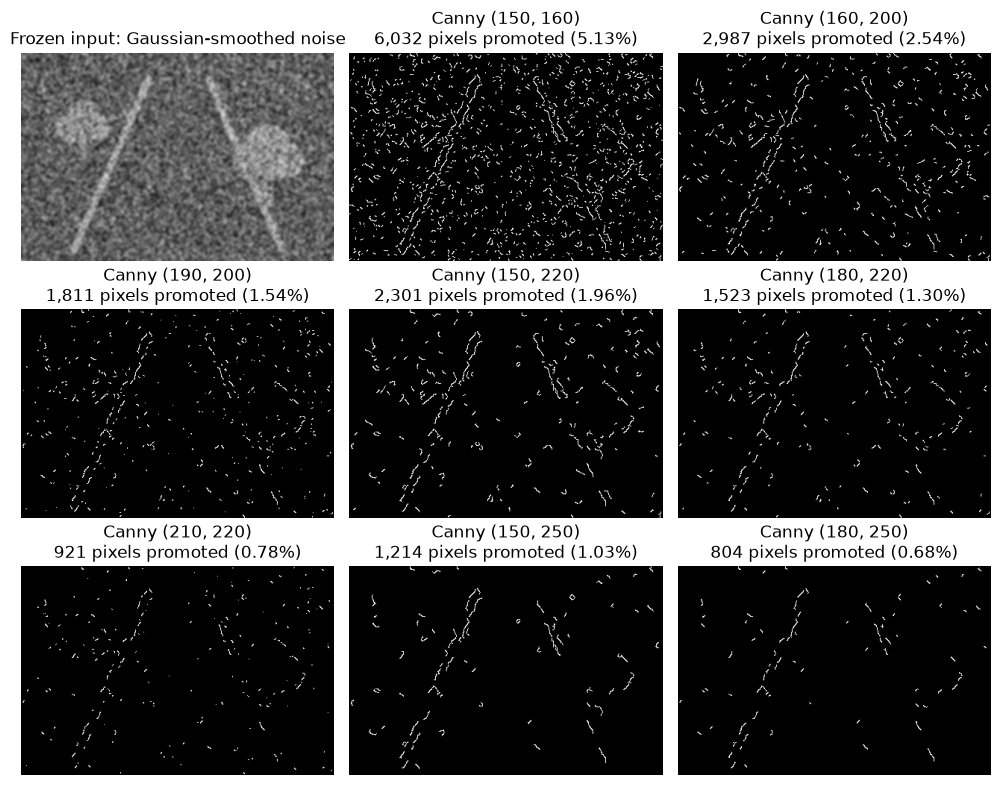

In [9]:
threshold_pairs = [
    (150, 160), (160, 200), (190, 200),
    (150, 220), (180, 220), (210, 220),
    (150, 250), (180, 250),
]

plot_canny_threshold_sweep(smoothed_versions["Gaussian"], threshold_pairs)

## 4. Least squares: the line of minimum collective embarrassment

Suppose the points almost form a line but measurement noise moves them around. For any proposed line, each point has a residual—here, its vertical distance from the line. Least squares chooses the line with the smallest **sum of squared residuals**.

Why squares? Positive and negative errors cannot cancel, and large mistakes receive a large penalty. That second property is useful until an outlier arrives with a dramatic personality: one enormous error can pull the fitted line toward it.

That is the whole idea required for this notebook. The algebra may continue existing independently without our supervision.

> In the rare, almost impossible case that this is not enough: Penn State's [Simple Linear Regression — What Is the Best Fitting Line?](https://online.stat.psu.edu/stat501/Lesson01) contains the derivation and formulas, while its serious name provides comfort through its mere existence.

> The synthetic witnesses and plotting machinery are hidden in the [notebook helpers](./_helpers/edges_hough_ransac.py).

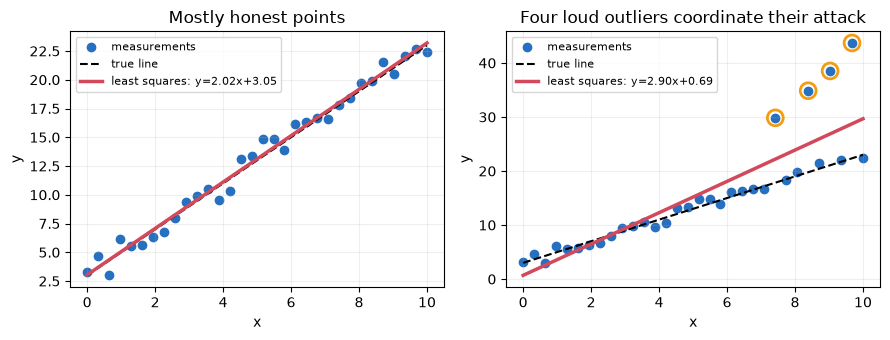

In [11]:
x_points, true_y, measured_y, observed_y, outlier_indices = make_line_points()

plot_least_squares_outliers(
    x_points, true_y, measured_y, observed_y, outlier_indices
);

## 5. RANSAC: trust small groups, then demand witnesses

**RANdom SAmple Consensus** repeatedly performs a small audition—in our experiment, up to 250 times:

1. Randomly pick two points, the minimum needed to define a 2D line.
2. Draw the only candidate line passing through them.
3. Measure how far every point is from that line.
4. Count the points within the allowed distance. Those supporters are **inliers**.
5. Remember the candidate supported by the most inliers. Some attempts find two honest points; others produce complete geometric nonsense.
6. After the auditions, take the winning inlier group and fit it with ordinary least squares to produce a cleaner final line.

RANSAC does not average its 250 candidate lines and it does not magically identify truth. It assumes that honest evidence is common enough for at least one lucky sample to contain only inliers. Its important knobs are the allowed residual distance and number of trials.

> The actual two-point RANSAC lives in [`fit_line_ransac()`](../../src/wave_part_dual/classical_cv/lines.py); its theatrical presentation lives with the [notebook helpers](./_helpers/edges_hough_ransac.py).

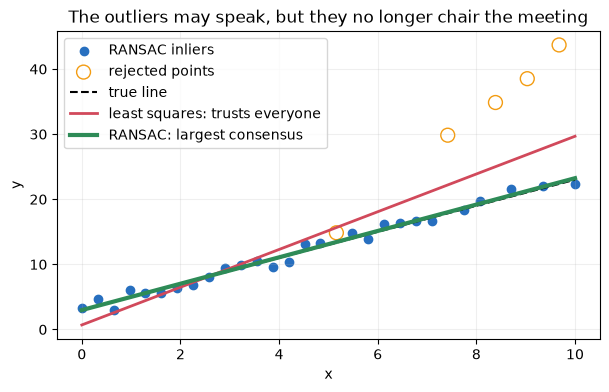

Least squares: slope=2.90, intercept=0.69
RANSAC:       slope=2.03, intercept=2.98
RANSAC kept 27 of 32 points as inliers


In [12]:
plot_ransac_result(
    x_points,
    true_y,
    observed_y,
    residual_threshold=1.3,
    trials=250,
    seed=5,
)

### Practice 3 — How forgiving should RANSAC be?

The `residual_threshold` is the maximum vertical distance from a candidate line that still earns a point the label **inlier**. A smaller value is strict: it rejects more noisy-but-honest points. A larger value is forgiving: it keeps more honest points but may also welcome an outlier wearing a convincing hat.

Below the points and random seed remain frozen while we vary two independent decisions: the threshold controls **which points support a candidate**, while the trial count controls **how many random two-point candidates get an audition**. With the same seed, the `10`-trial run uses the same first 10 attempts as the `250`-trial run; the longer run simply receives 240 additional chances to get lucky.

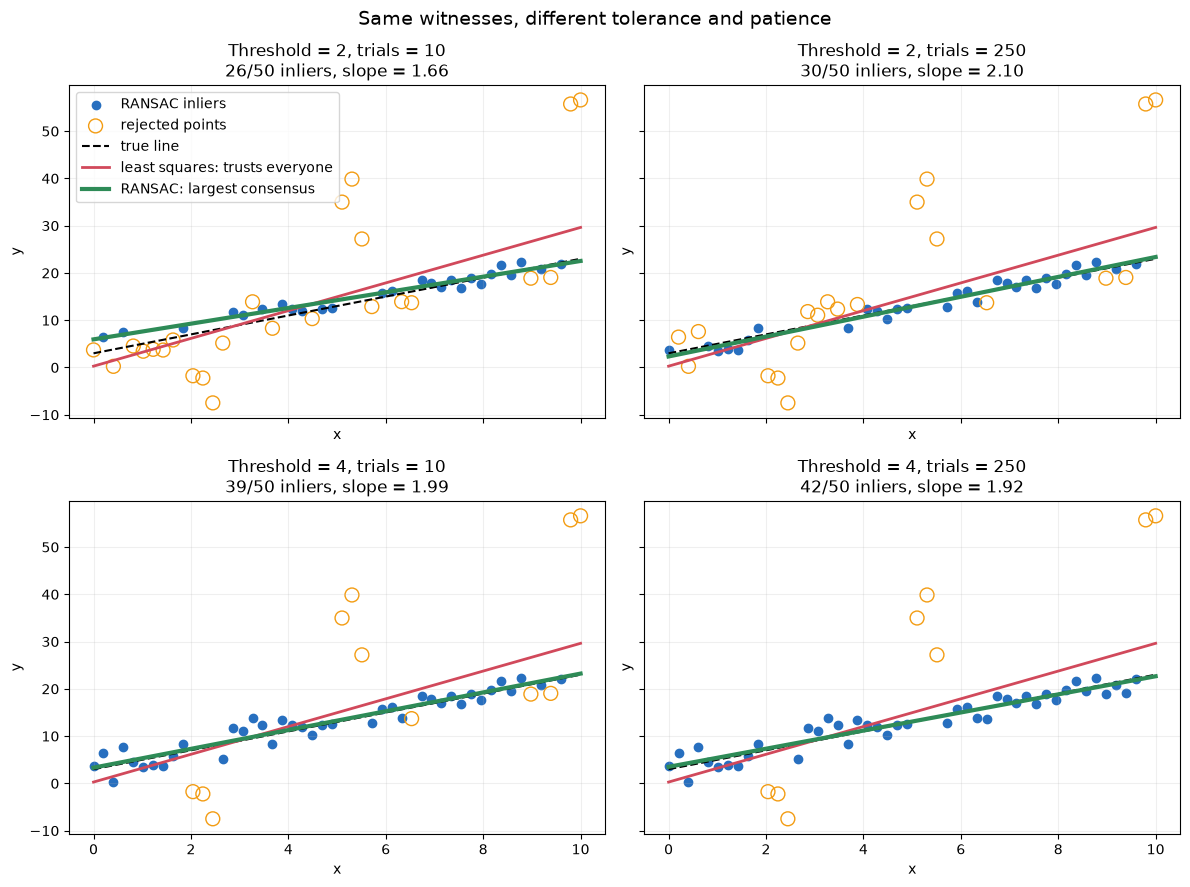

Least squares: slope=2.94, intercept=0.28
RANSAC threshold=2, trials=10: slope=1.66, intercept=5.95, inliers=26/50
RANSAC threshold=2, trials=250: slope=2.10, intercept=2.33, inliers=30/50
RANSAC threshold=4, trials=10: slope=1.99, intercept=3.33, inliers=39/50
RANSAC threshold=4, trials=250: slope=1.92, intercept=3.50, inliers=42/50


In [13]:
x_points_p, true_y_p, _, observed_y_p, _ = make_line_points(
    points_count=50,
    noise_sigma=2,
    outlier_indices=(10, 11, 12, 25, 26, 27, 48, 49),
    outlier_offsets=(-10, -11, -12, 20, 26, 10, 33, 34),
)
residual_thresholds_p = (2, 4)
trial_counts_p = (10, 250)
ransac_seed_p = 6

plot_ransac_parameter_grid(
    x_points_p,
    true_y_p,
    observed_y_p,
    residual_thresholds_p,
    trial_counts_p,
    seed=ransac_seed_p,
)

Here 10 trials are not quite enough. At threshold `2`, the longer search finds four more supporters and moves the slope from `1.66` to `2.10`; at threshold `4`, it finds three more and changes `1.99` to `1.92`. More trials provide extra chances to find a stronger consensus, while the wider threshold changes who is allowed into that consensus. Neither knob promises truth, but both are now visibly doing something.

## 6. Hough transform: let every edge pixel vote

The mysterious name is simply inherited from its inventor, Paul Hough. It is a surname, not an acronym designed to frighten innocent image pixels.

A line is represented by its angle `θ` and perpendicular distance `ρ` from the origin. We do not ask every image pixel to participate—only the white **edge pixels** produced by Canny. One such pixel could belong to many possible lines, so it votes for every `(θ, ρ)` pair describing a line through it. In our simple implementation, that means trying every allowed angle and calculating the one `ρ` that makes the line pass through the pixel.

One image point therefore becomes a curve in Hough parameter space. Points lying on the same image line produce curves that cross at one shared `(θ, ρ)`. A busy crossing in the vote accumulator means: *many edge pixels agree that this line exists.*

A useful mental model is an election: **a pixel does not know which line it belongs to, so it votes for every plausible one. Real lines win because many pixels independently vote for the same answer.** The accumulator plot is the election result—bright spots are winning lines; the darker regions are unsuccessful geometric political parties.

> It sounds unnecessarily abstract until the curves meet. Then it becomes merely strange. [OpenCV Hough line tutorial](https://docs.opencv.org/4.x/d6/d10/tutorial_py_houghlines.html).

> The educational vote counter lives in [`hough_accumulator()`](../../src/wave_part_dual/classical_cv/lines.py). If plotting sinusoidal political campaigns becomes your calling, consult the [notebook helpers](./_helpers/edges_hough_ransac.py).

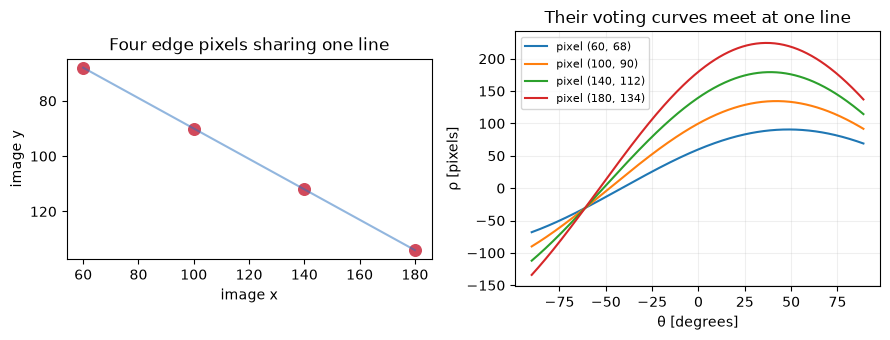

In [14]:
line_x = np.array([60, 100, 140, 180])
line_y = 0.55 * line_x + 35
theta_degrees = np.linspace(-90, 89, 360)

plot_hough_voting_curves(line_x, line_y, theta_degrees)

### From votes to detected lines

The accumulator is just a 2D table indexed by `(ρ, θ)`. Every edge pixel adds votes. Bright peaks are parameter pairs supported by many pixels. OpenCV then performs the same general idea efficiently and can return finite line segments with `HoughLinesP`.

The threshold is political: a low value allows minor parties and nonsense lines; a high value recognizes only candidates with a large coalition.

> OpenCV handles the serious detection; the figure assembly is concealed in the [notebook helpers](./_helpers/edges_hough_ransac.py) for public safety.

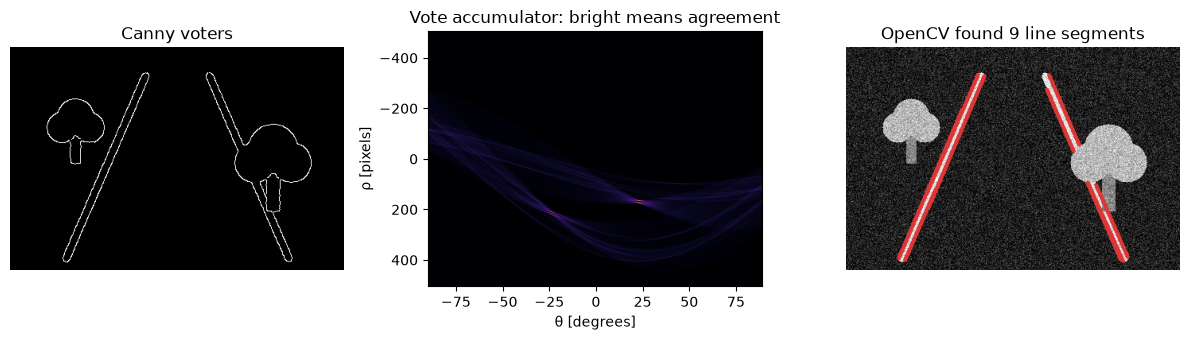

In [15]:
detected_segments = plot_hough_detection(
    edge_map,
    noisy_scene,
    threshold=55,
    min_length=70,
    max_gap=18,
)

**Why nine segments when the scene has only two road markings?** A thick marking gives Canny two edges, and one physical edge may be returned as several overlapping or disconnected segments. Straight pieces of other objects may also qualify. `HoughLinesP` reports every fragment that passes `threshold`, `minLineLength`, and `maxLineGap`; it does not yet understand that several fragments belong to the same civilized road boundary.

Below each returned segment has its own color and number; where colors lie almost on top of one another, OpenCV has reported overlapping opinions about the same physical edge. 

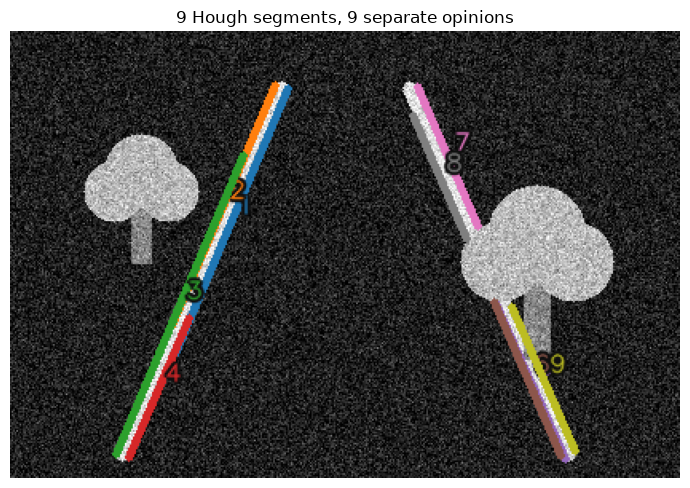

In [16]:
plot_numbered_hough_segments(noisy_scene, detected_segments)

### Practice 4 — HoughLinesP control panel

Keep the Canny voters frozen and change one Hough control at a time:

- `threshold`: minimum vote support required before a possible line is considered. Lower means *listen to weaker coalitions*.
- `minLineLength`: reject returned segments shorter than this many pixels. Lower means *small straight fragments may enter*.
- `maxLineGap`: join aligned fragments separated by at most this many pixels. Higher means *please assume those missing pixels were merely on lunch break*.

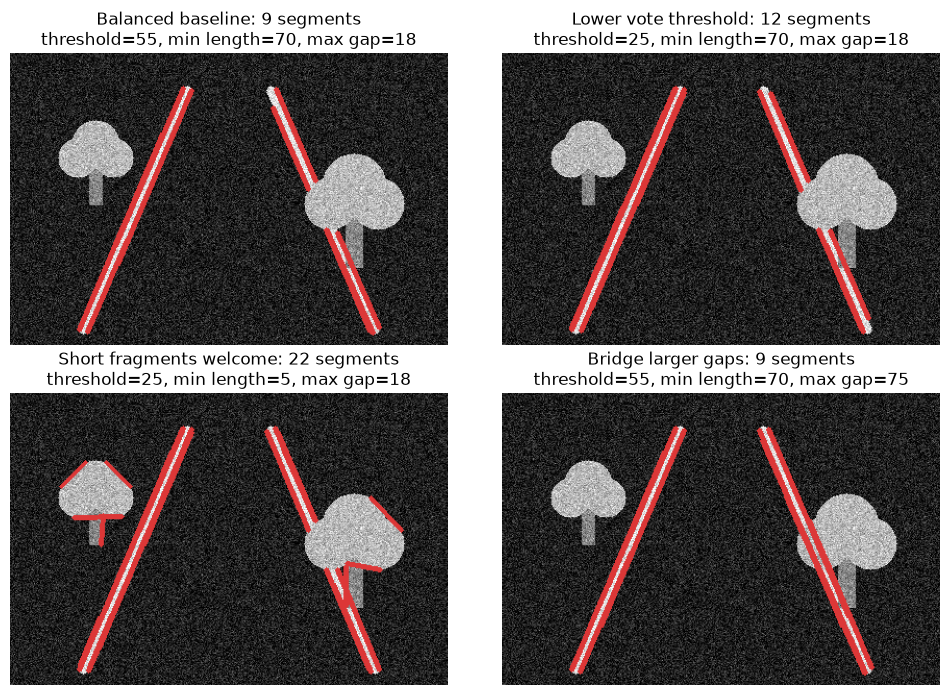

In [17]:
hough_practice_configs = [
    ("Balanced baseline", 55, 70, 18),
    ("Lower vote threshold", 25, 70, 18),
    ("Short fragments welcome", 25, 5, 18),
    ("Bridge larger gaps", 55, 70, 75),
]

plot_hough_parameter_grid(edge_map, noisy_scene, hough_practice_configs)

The controls interact. Lowering `threshold` admits three additional line opinions. Lowering only `minLineLength` changes nothing here because `threshold=55` remains the stricter bouncer: a very short fragment cannot gather enough votes anyway. Increasing `maxLineGap` keeps the count at nine but joins the right road boundary across the tree's interruption—helpful gap recovery, with a small willingness to imagine a line continuing behind foliage.

## 7. Hough and RANSAC are related, not interchangeable

- **Hough:** many edge pixels vote in a discretized parameter space. It is excellent for finding several lines or shapes in an image, but resolution and thresholds affect the result.
- **RANSAC:** repeatedly proposes a model from a minimal random sample and asks how many data points support it. It is excellent when a point set contains outliers and we want one or a few models.
- **Least squares:** uses all points and gives a clean final estimate when the evidence is mostly honest. It is often used *after* RANSAC identifies the inliers.

A practical pipeline may use edges to generate evidence, Hough or RANSAC to discover structure, and least squares to polish the survivors. The algorithms are colleagues, not rival cults.

## Quick reflection

- Why can smoothing help edge detection, and what detail can it destroy?
    - It suppresses noisy intensity changes, but it can also blur weak edges and small details until they disappear.
- Why does Sobel X emphasize mostly vertical borders?
    - It measures brightness change from left to right, which is strongest when crossing a vertical border.
- Why can a few distant outliers pull a least-squares line strongly?
    - Squaring residuals gives very large errors enormous influence, so dramatic outliers receive far too much attention.
- What does an inlier mean to RANSAC?
    - It is a point close enough to the current candidate model according to the chosen residual threshold.
- What does a bright peak in a Hough accumulator mean?
    - Many edge pixels voted for the same line parameters, so they probably share a line in the image.
- When might you choose Hough instead of RANSAC?
    - Hough is convenient for finding several lines directly from an edge image; RANSAC is useful when fitting a model to points containing outliers.

## Takeaway

Filters convert local pixel neighbourhoods into useful evidence. Hough gathers votes from many edge pixels; RANSAC searches for a model with a trustworthy crowd; least squares gives that crowd a precise final line.

The pixels were noisy, the outliers lied, and geometry survived anyway.